# Process the goggles-gratings session

Builds the `GratingDevice` (binocular phase-disparity **drifting grating**), runs
`GratingSessionAnalyzer.analyze_session_stats`, and saves
`{session_name}_dataframe.pkl` next to the session data. The df is **long**
(one row per cell x disparity) with per-disparity split-half reliability and a
full-field response magnitude (`response_mean` / `response_sem`) — a **disparity
tuning curve**.

The grating is full-field and drifts in time, so there is **no spatial RF**: the
sweep-geometry methods (`get_angle_range`, `get_screen_range`, ...) raise
`NotImplementedError` on purpose.

Run this in its own kernel with **only** `disparity-analysis` on `sys.path`
(`radial-analysis` and `disparity-analysis` both define a `src.analysis.CellAnalysis`).

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

from src.data.GratingDevice import GratingDevice
from src.analysis.GratingAnalysis import GratingSessionAnalyzer

%load_ext autoreload
%autoreload 2

In [2]:
mouse, date, experiment = "SAM045", "260721", "goggles-gratings"
G = GratingDevice(mouse_name=mouse, record_date=date, experiment_name=experiment)
print("session:", G.session_name, "| disparities:", G.disparities,
      "| temp_freq:", G.temp_freq, "| cells:", len(G.suite2p_id))

Directory results already exists
session: 260721_SAM045_goggles-gratings | disparities: [-5, 0, 5, 10, 15] | temp_freq: 2 | cells: 1305


In [3]:
# load cached stats if present, else compute once (slow) and save the pkl
pkl_path = os.path.join(G.data_dir, f"{G.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = GratingSessionAnalyzer(G).analyze_session_stats(n_iterations=200)
    GratingSessionAnalyzer(G).save_dataframe(stats_df)   # -> pkl_path
stats_df.head()

Saved DataFrame to: D:/data-distance-coding-project/processed-data\260721_SAM045_goggles-gratings\260721_SAM045_goggles-gratings_dataframe.pkl


,cell,session_name,disparity,reliable,mean_corr,response_mean,response_sem,n_trials
0,0,260721_SAM045_goggles-gratings,-5,False,0.369319,-0.122599,0.106986,12
1,0,260721_SAM045_goggles-gratings,0,False,0.166810,-0.102236,0.121425,12
2,0,260721_SAM045_goggles-gratings,5,False,0.687884,-0.198660,0.053123,12
3,0,260721_SAM045_goggles-gratings,10,False,0.672636,-0.170194,0.093115,12
4,0,260721_SAM045_goggles-gratings,15,False,0.671585,-0.355868,0.061831,12


171 cells reliable at >= 1 disparity


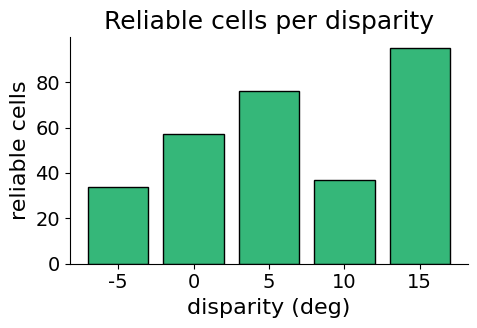

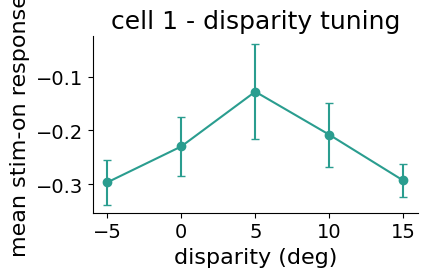

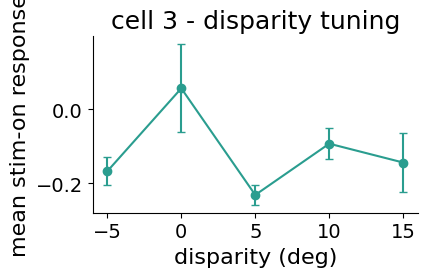

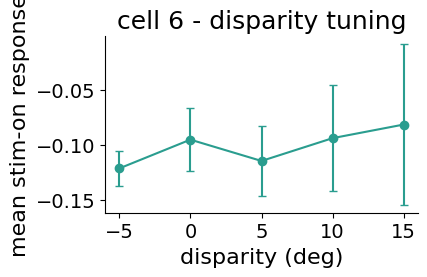

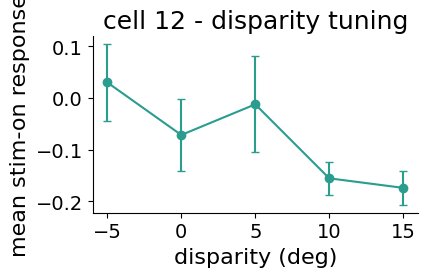

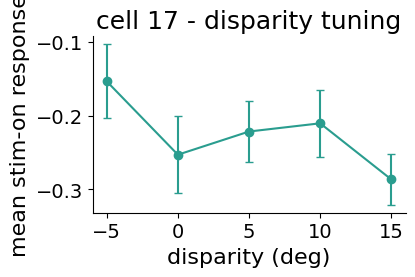

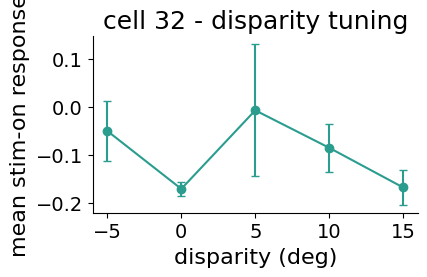

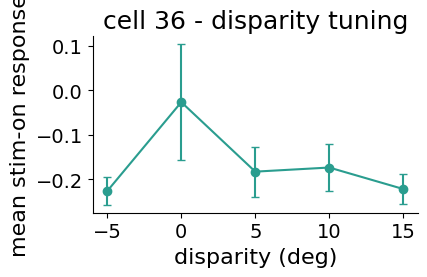

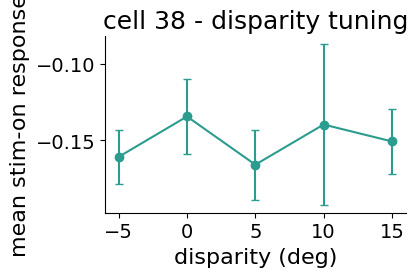

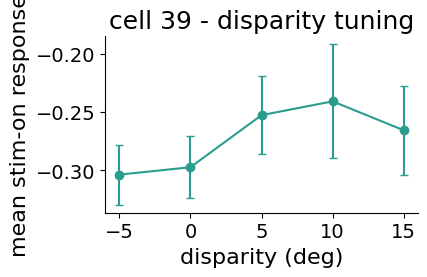

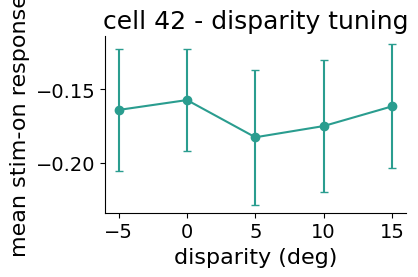

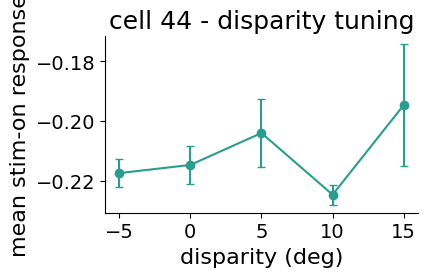

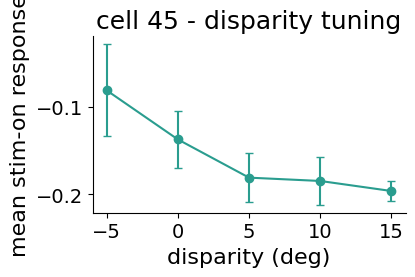

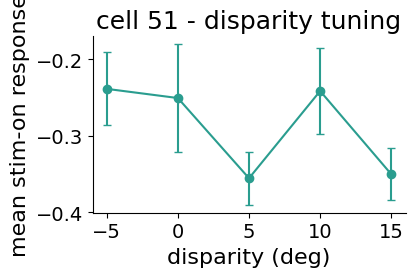

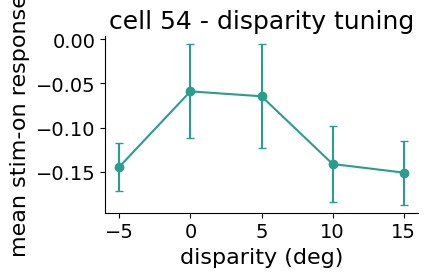

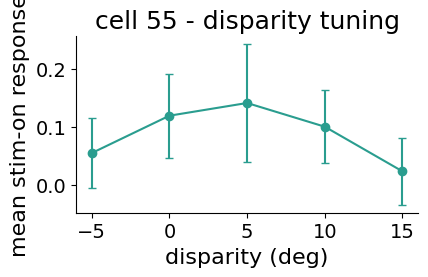

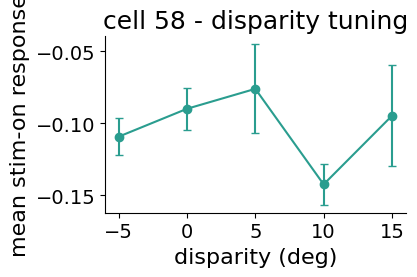

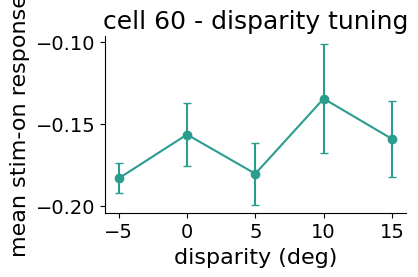

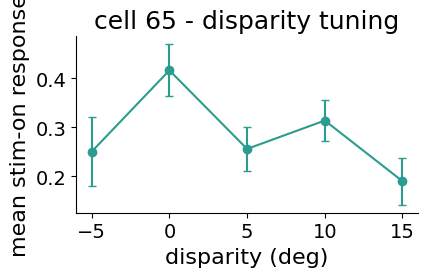

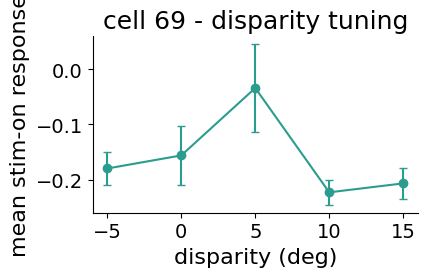

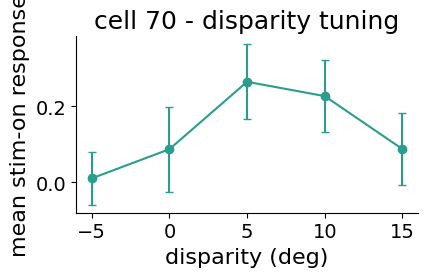

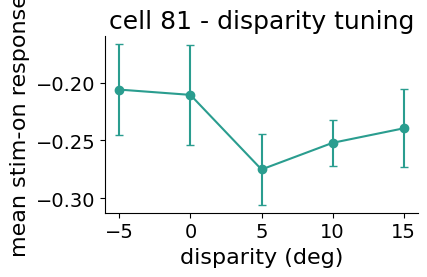

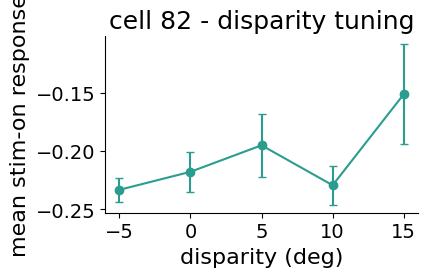

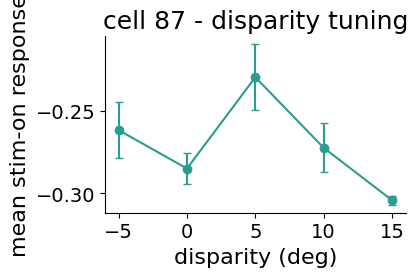

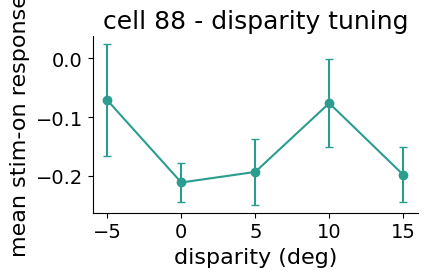

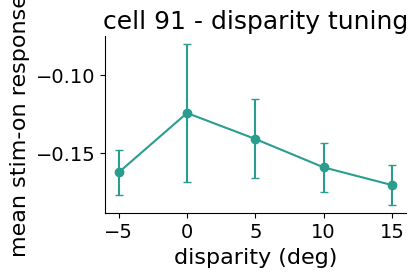

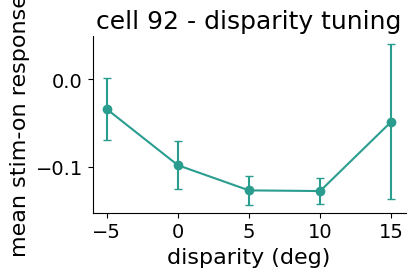

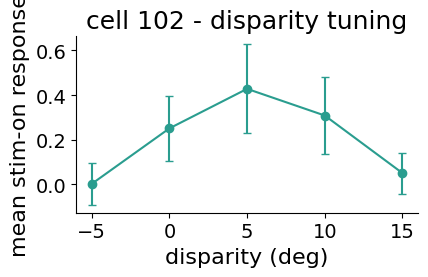

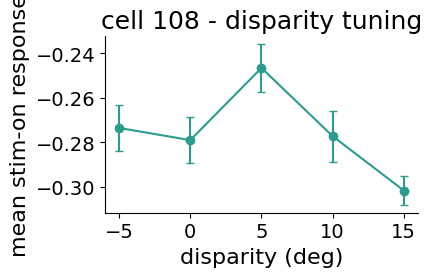

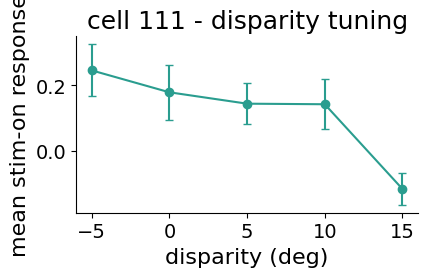

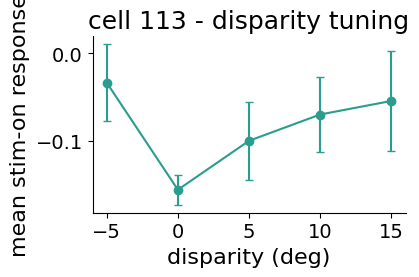

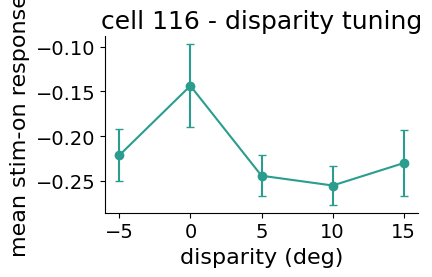

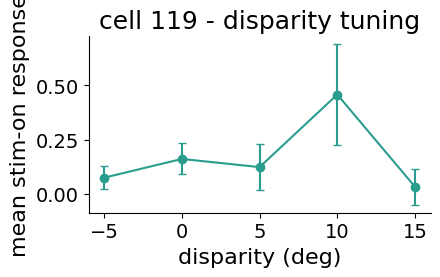

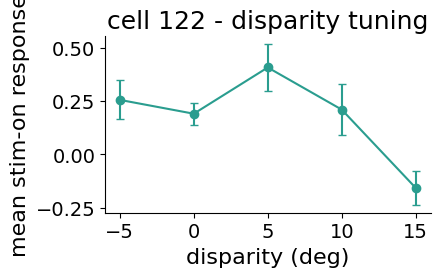

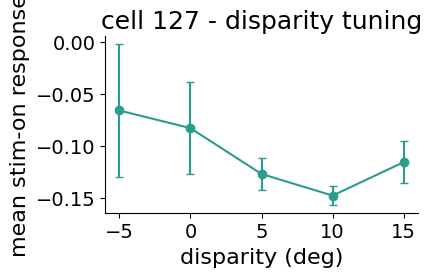

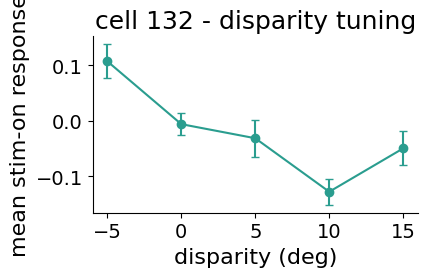

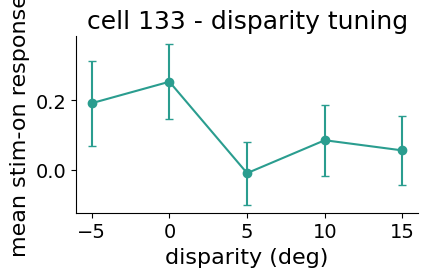

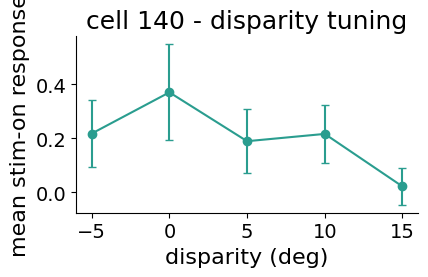

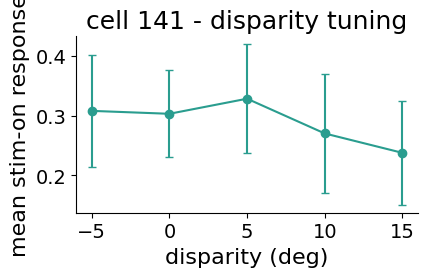

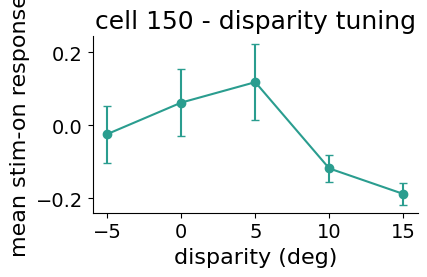

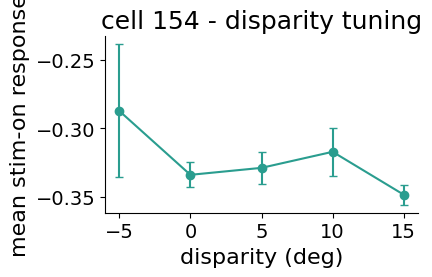

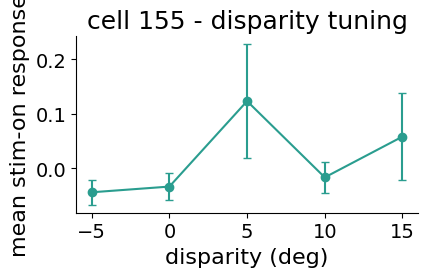

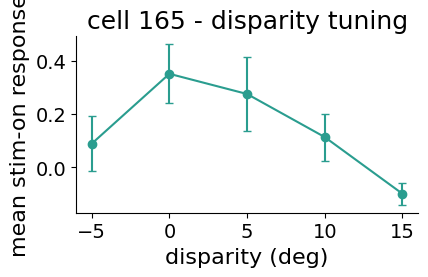

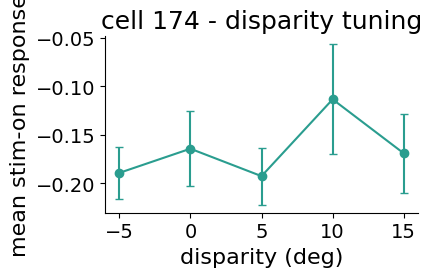

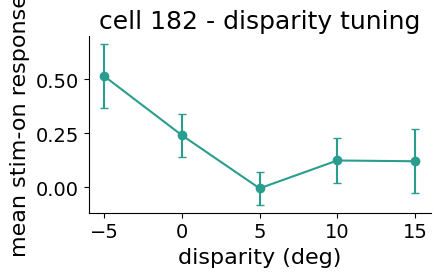

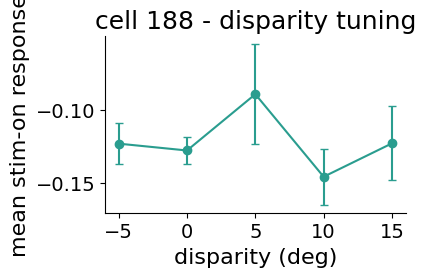

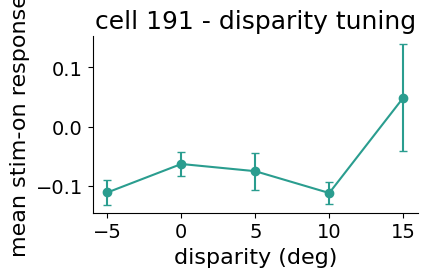

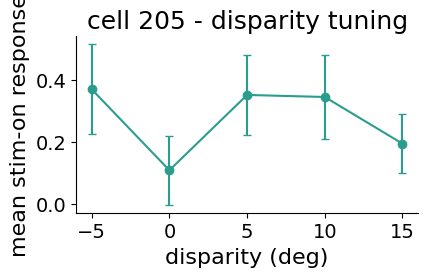

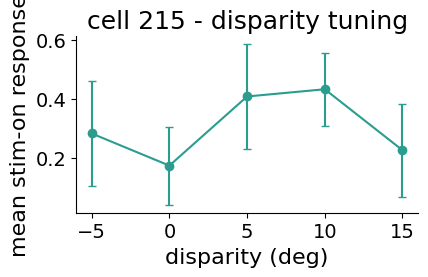

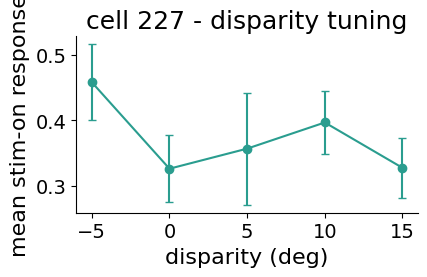

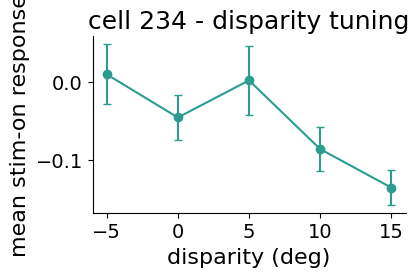

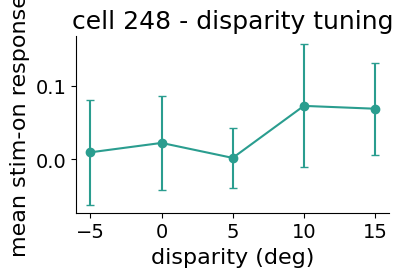

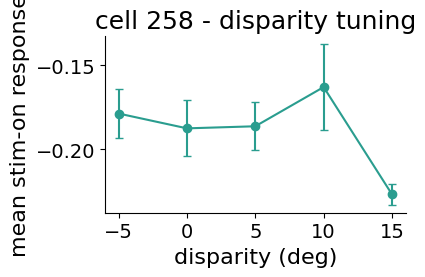

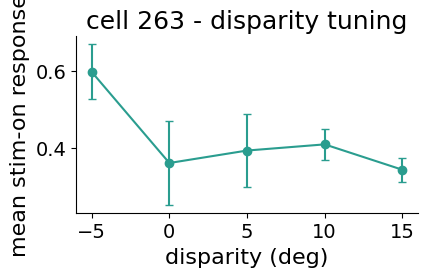

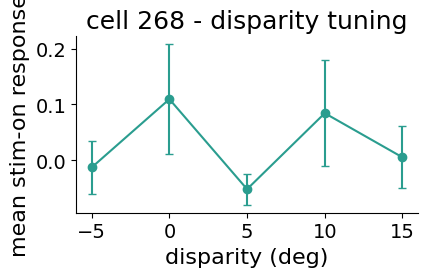

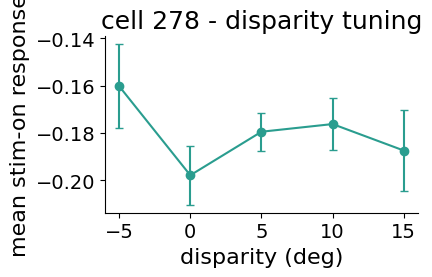

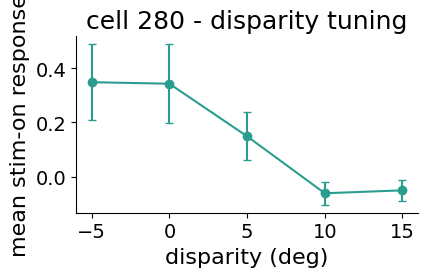

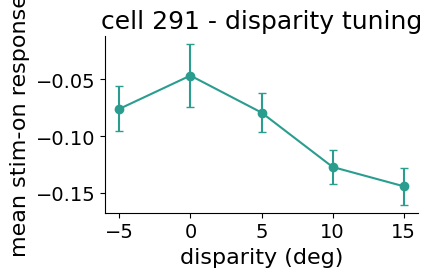

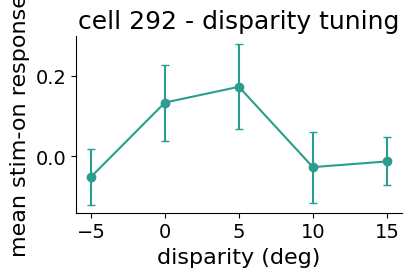

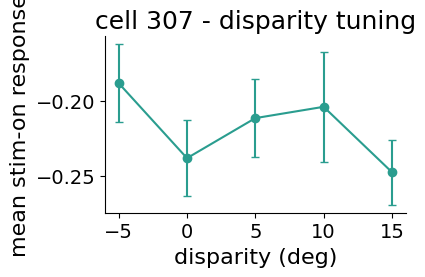

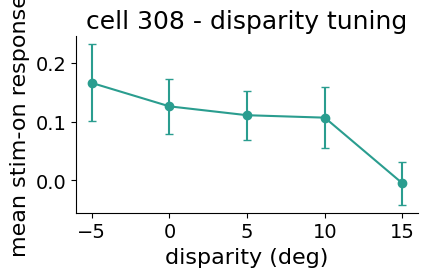

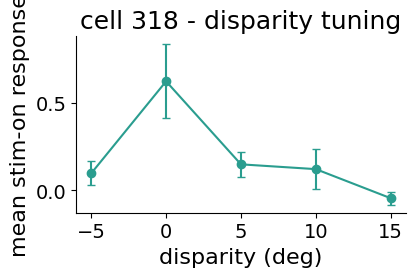

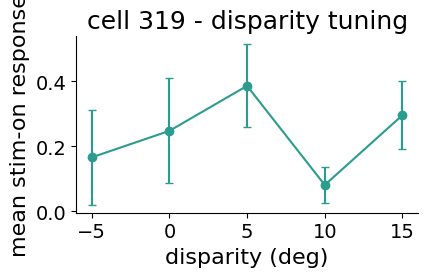

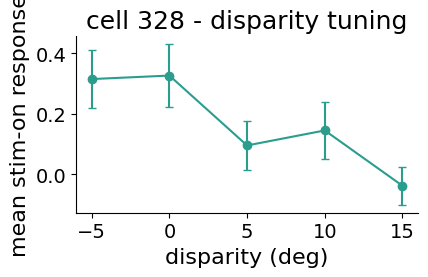

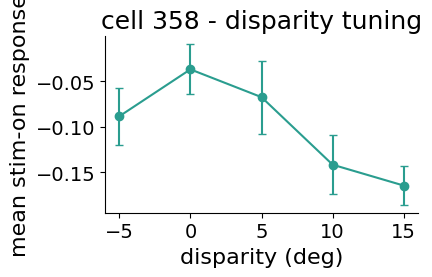

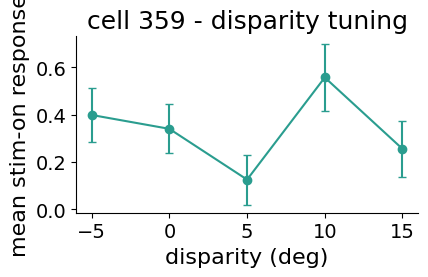

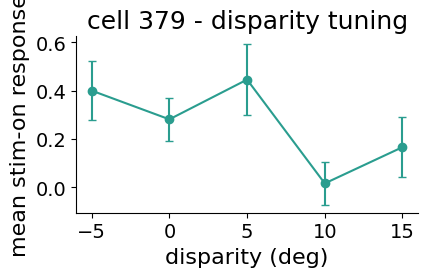

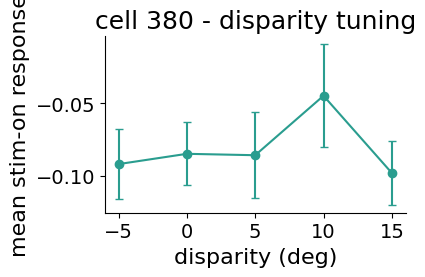

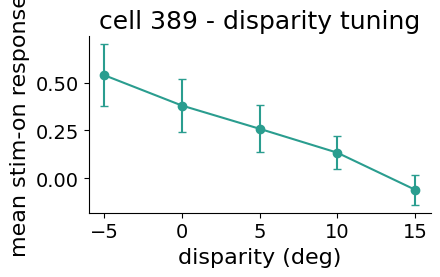

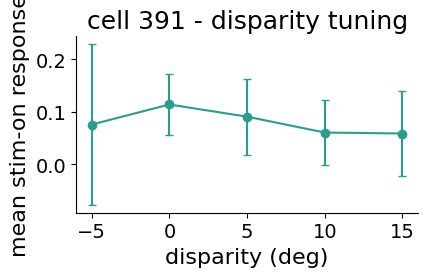

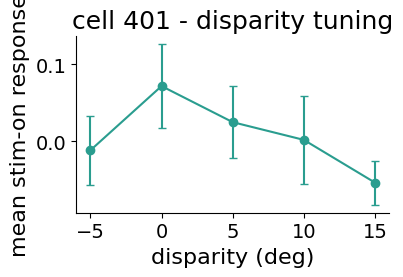

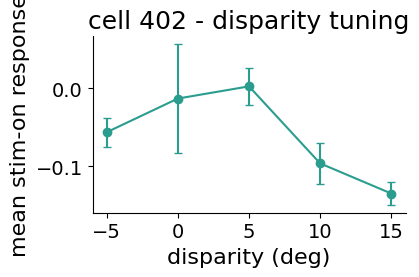

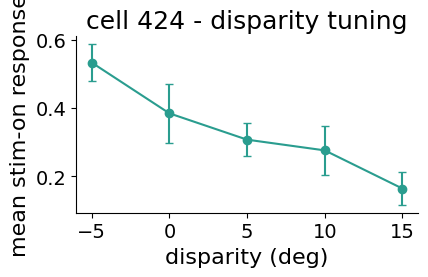

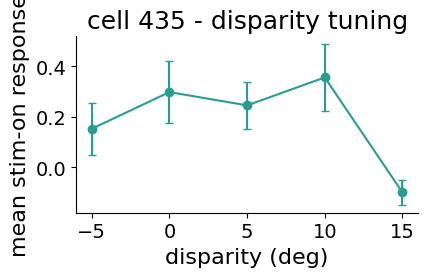

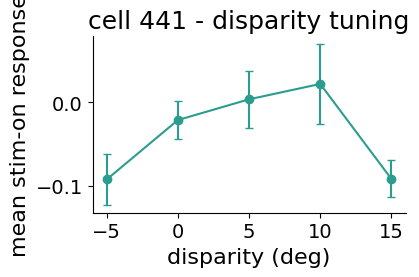

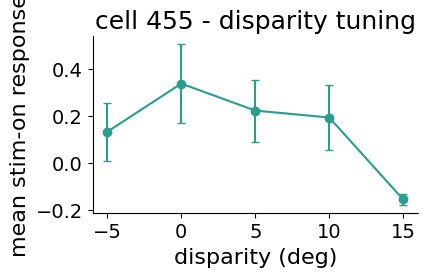

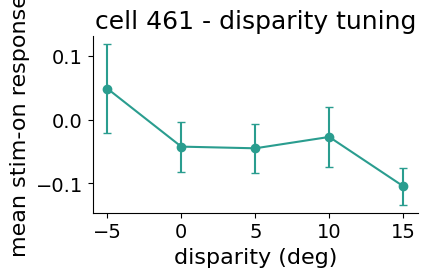

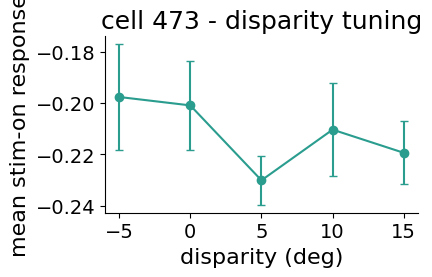

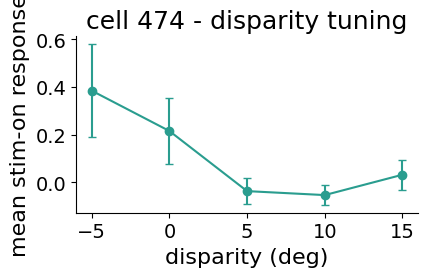

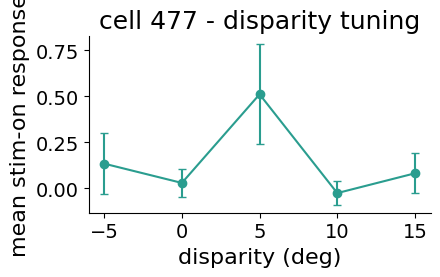

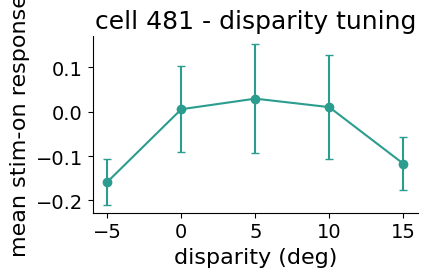

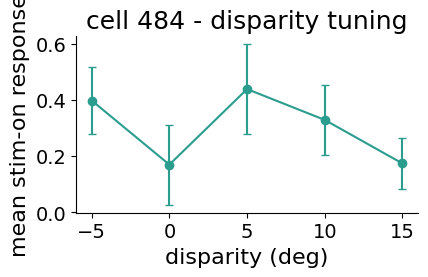

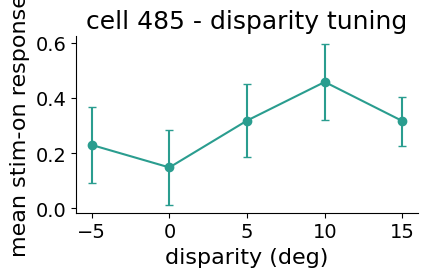

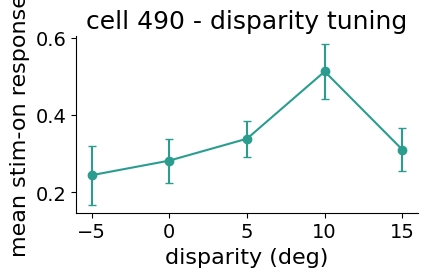

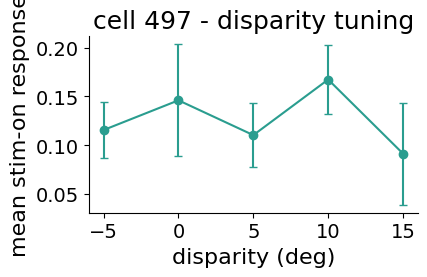

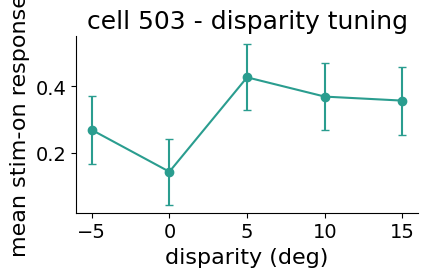

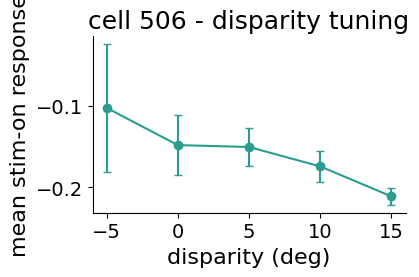

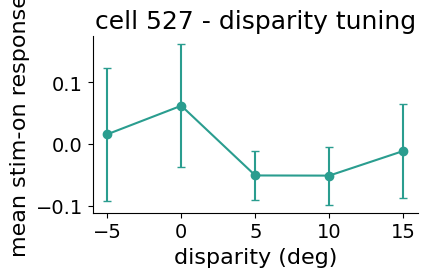

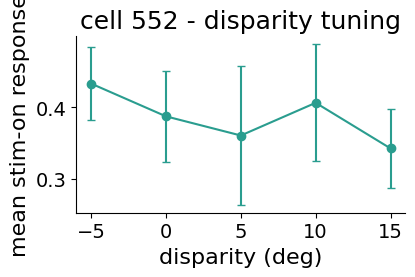

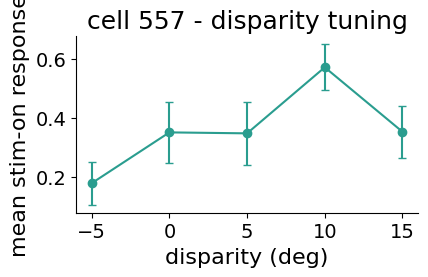

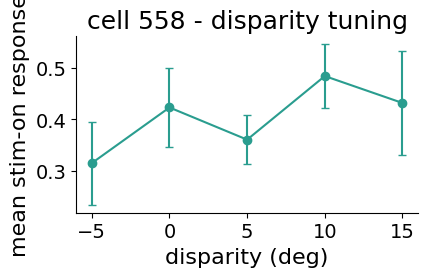

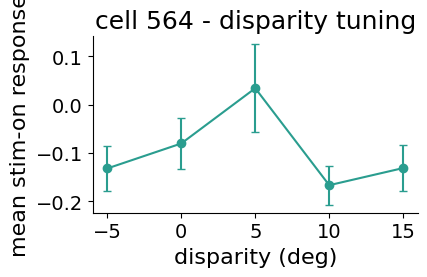

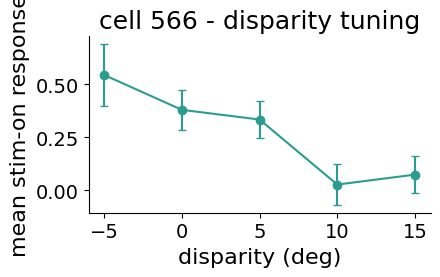

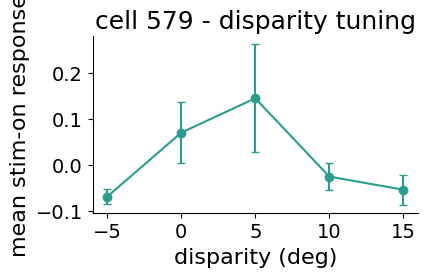

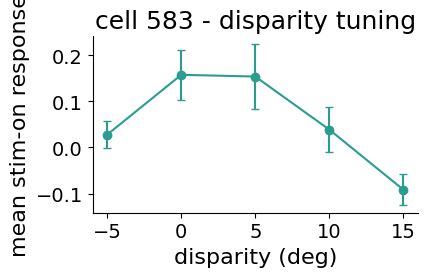

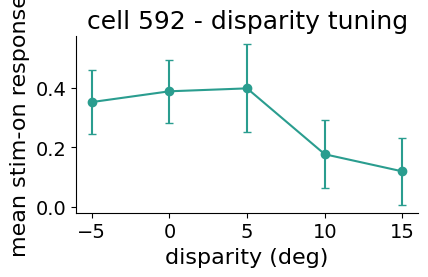

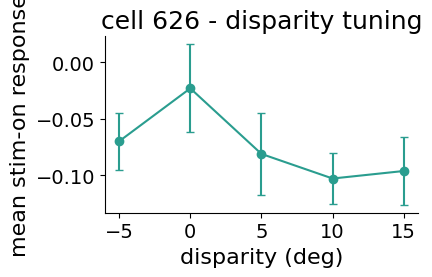

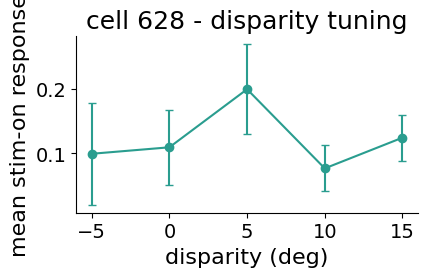

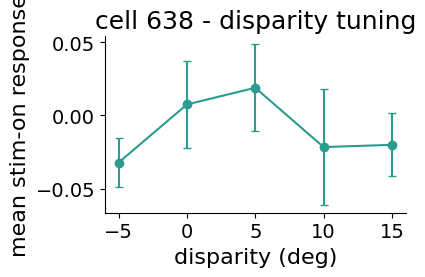

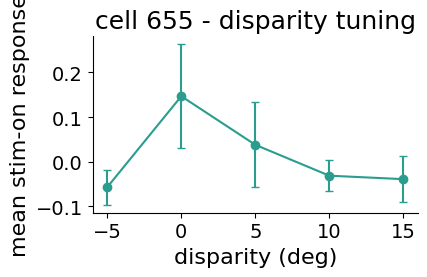

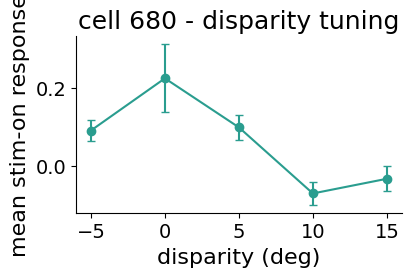

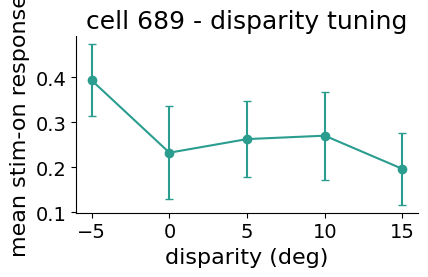

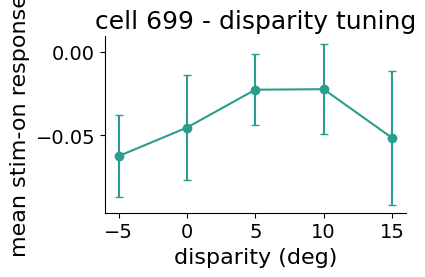

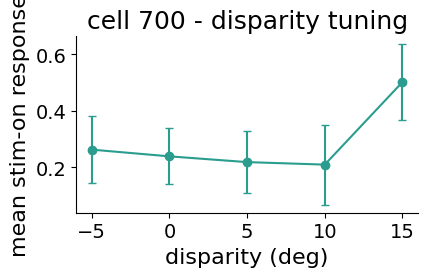

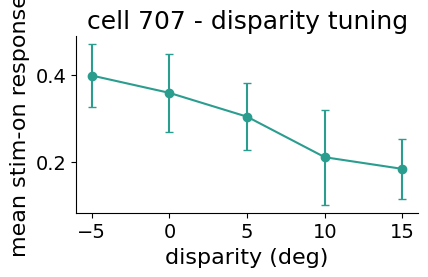

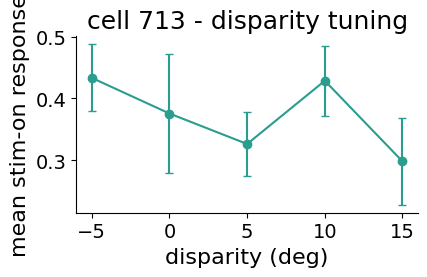

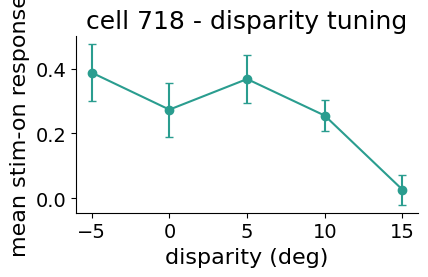

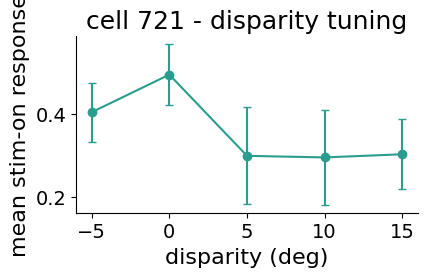

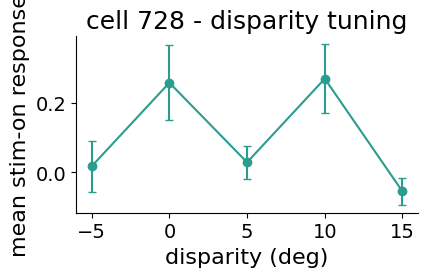

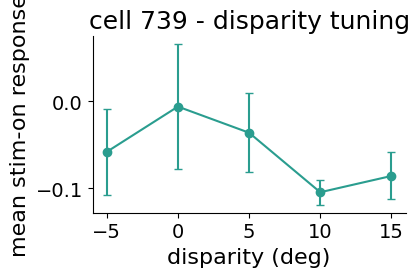

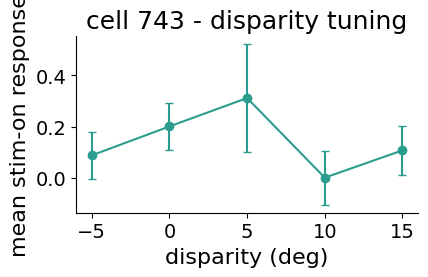

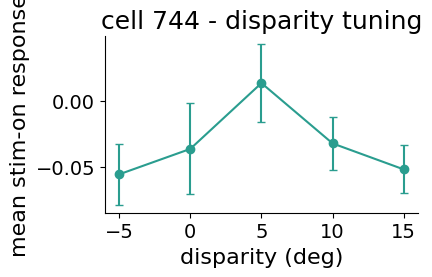

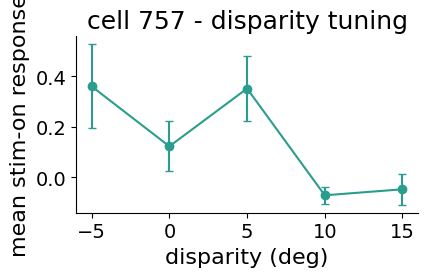

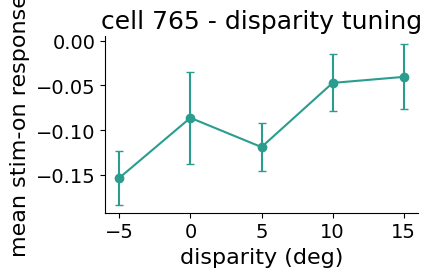

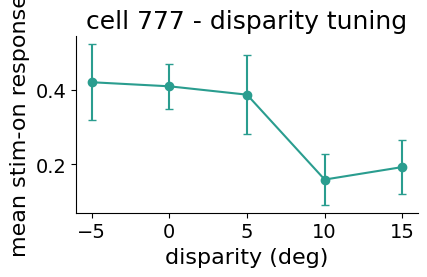

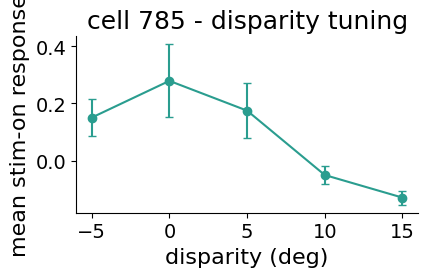

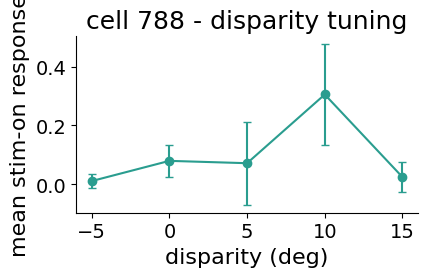

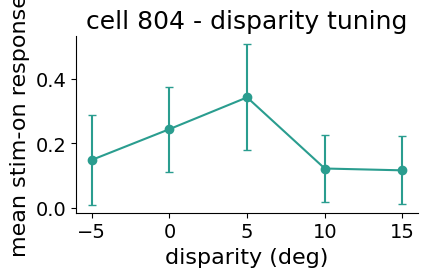

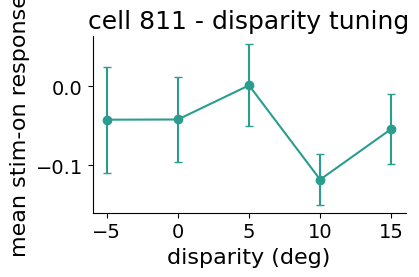

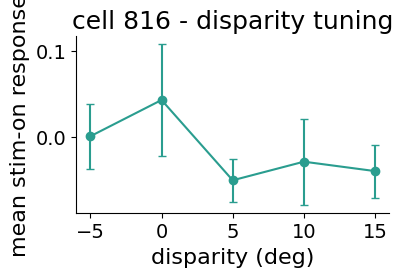

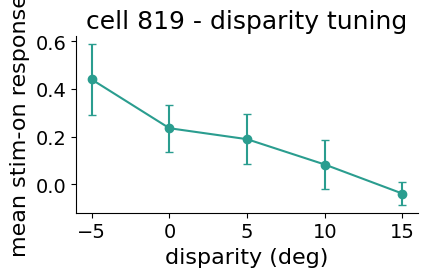

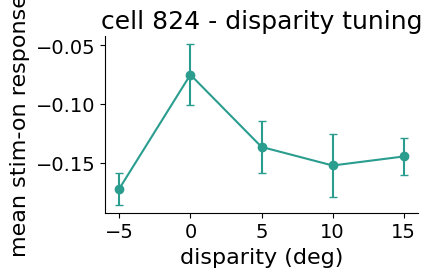

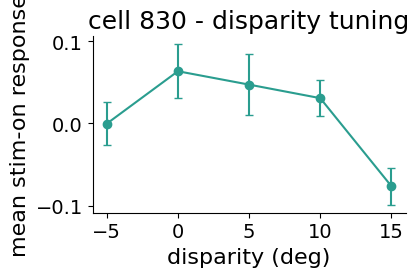

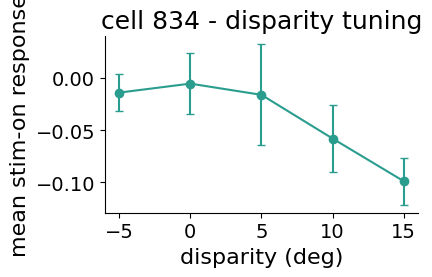

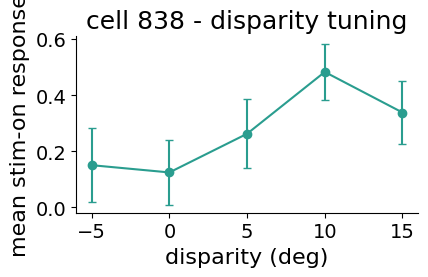

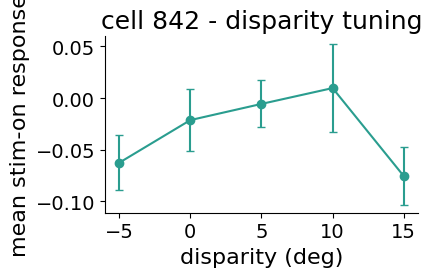

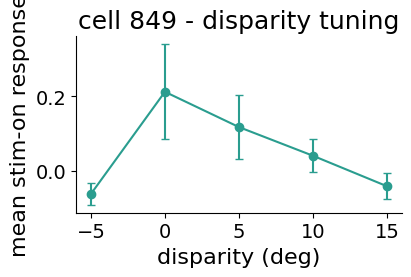

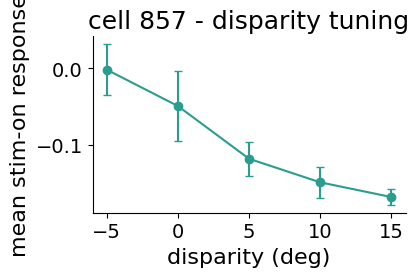

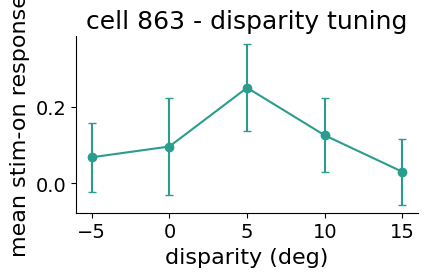

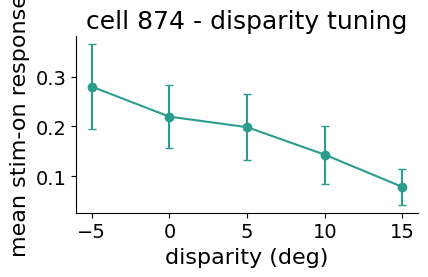

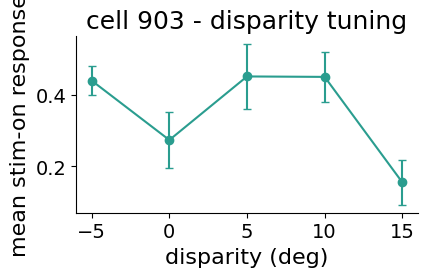

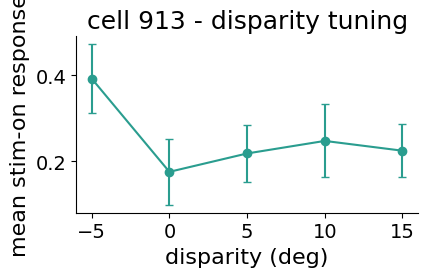

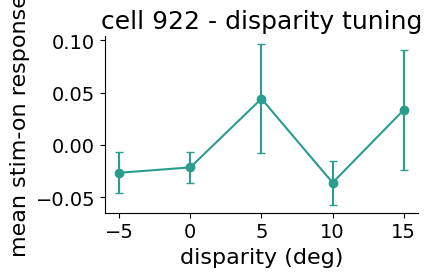

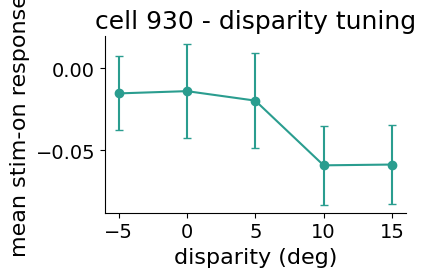

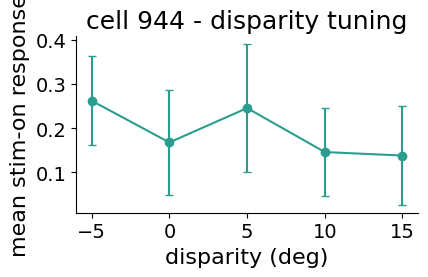

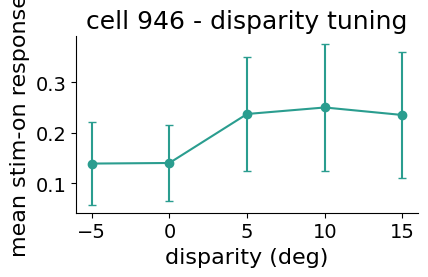

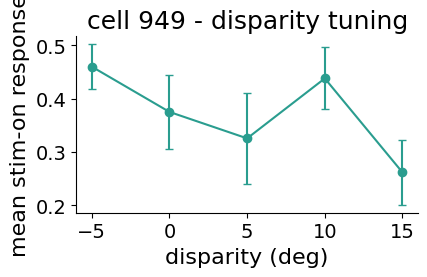

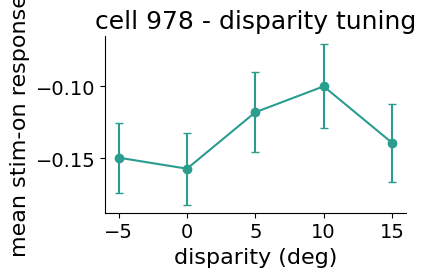

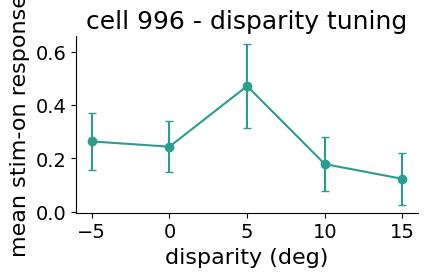

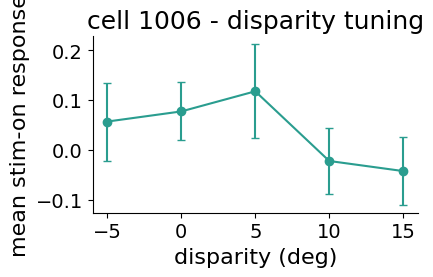

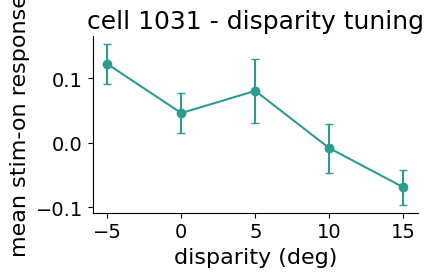

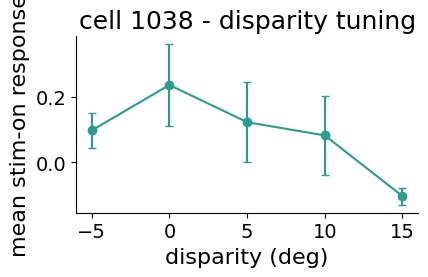

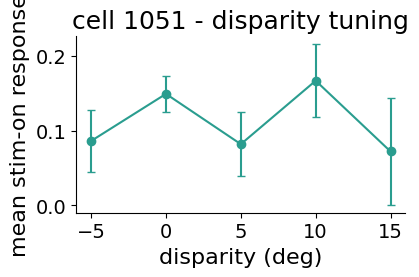

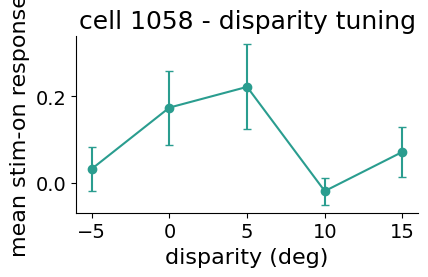

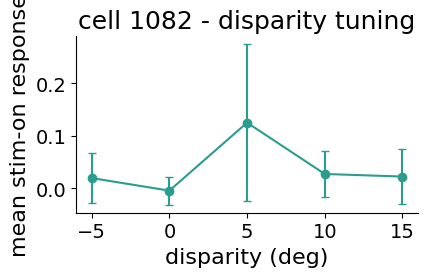

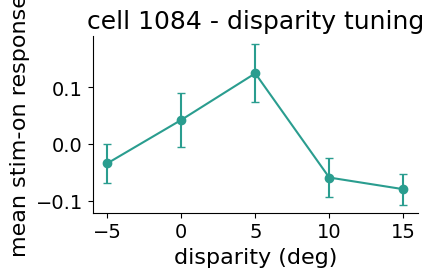

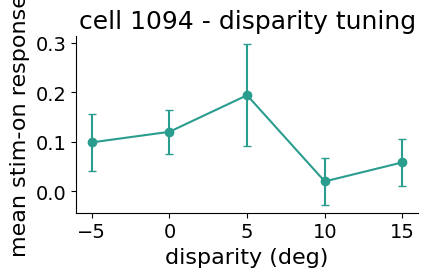

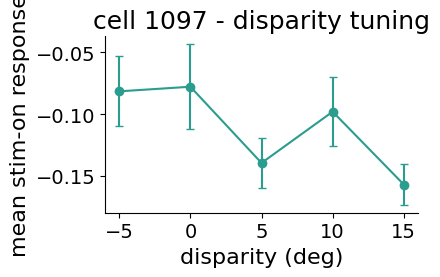

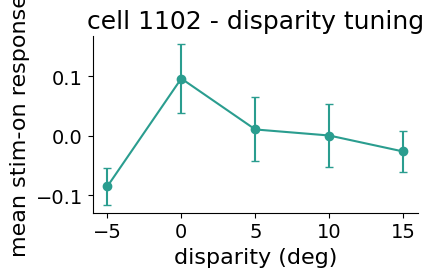

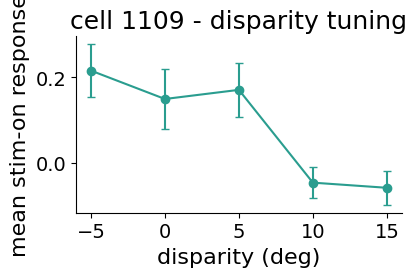

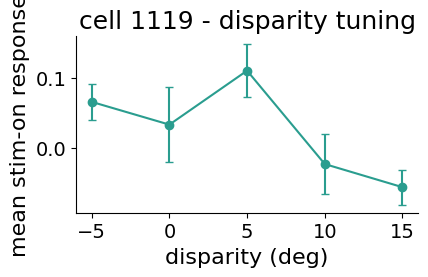

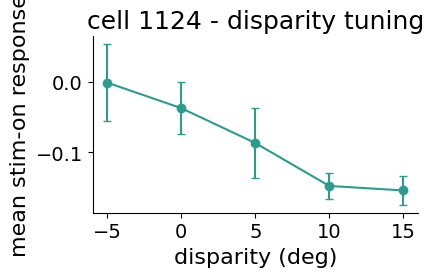

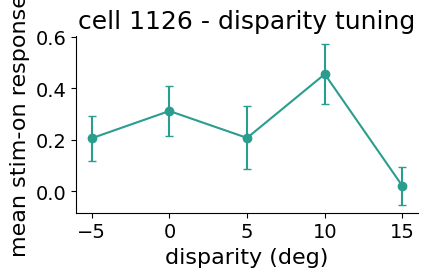

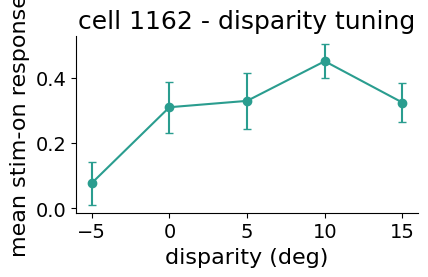

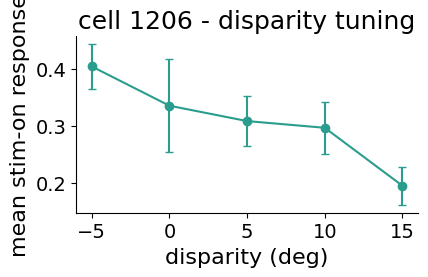

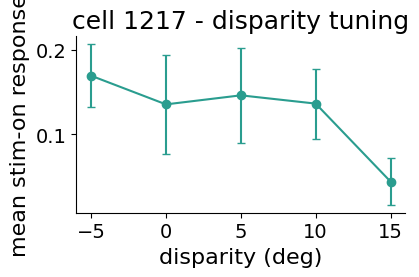

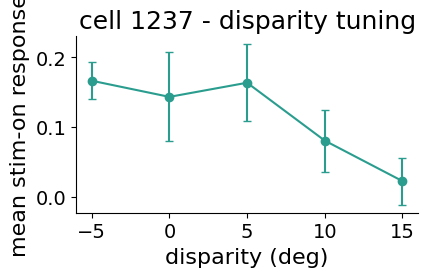

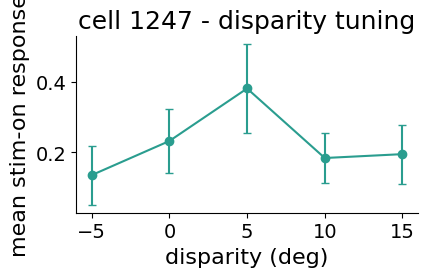

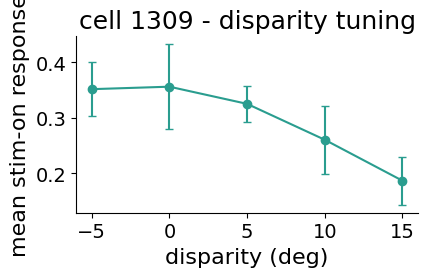

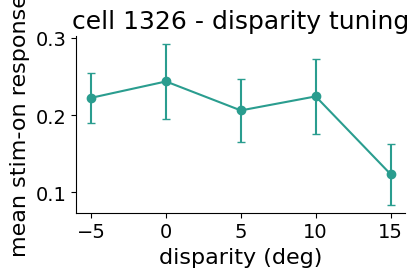

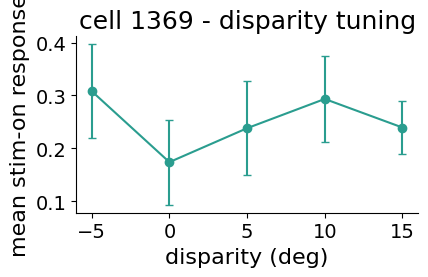

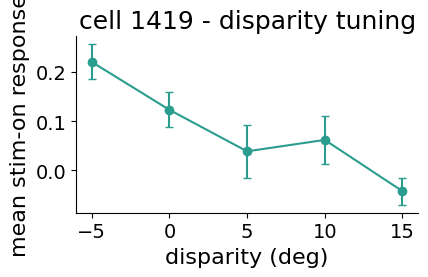

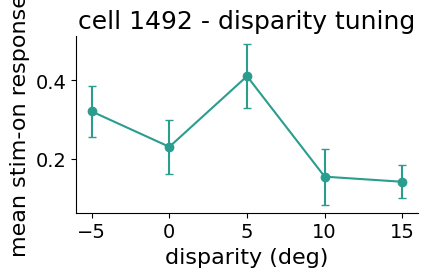

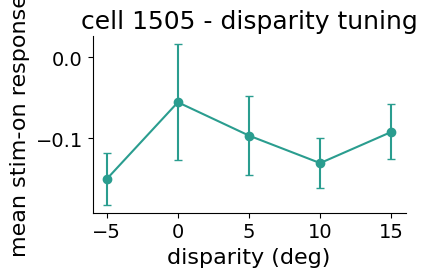

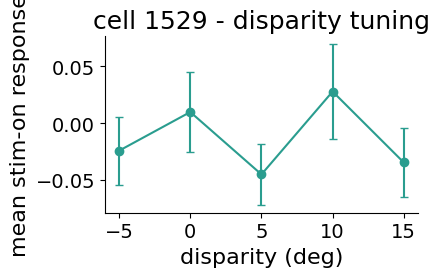

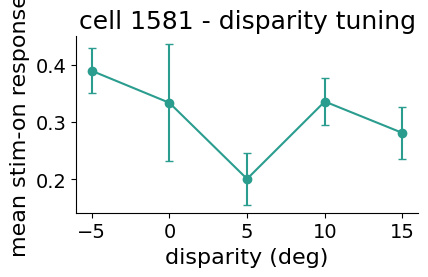

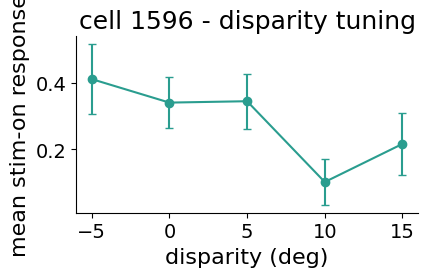

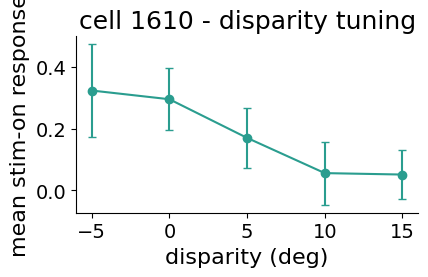

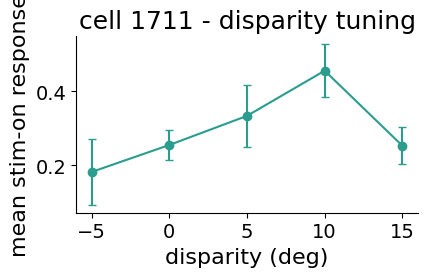

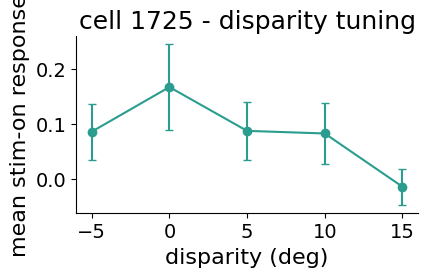

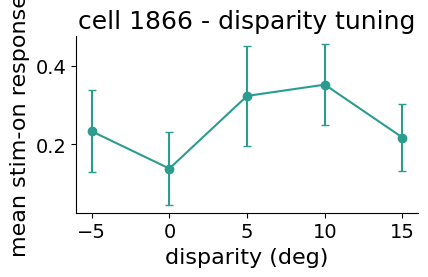

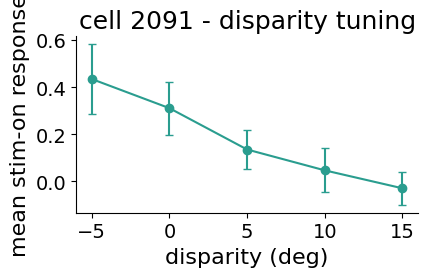

In [5]:
# --- sanity check: reliable cells per disparity + a few disparity tuning curves ---
reliable_cells = sorted(stats_df.loc[stats_df['reliable'], 'cell'].unique())
print(f"{len(reliable_cells)} cells reliable at >= 1 disparity")

counts = stats_df[stats_df['reliable']].groupby('disparity')['cell'].nunique()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index.astype(str), counts.values, color='#35b779', edgecolor='black')
ax.set_xlabel('disparity (deg)'); ax.set_ylabel('reliable cells')
ax.set_title('Reliable cells per disparity'); plt.tight_layout(); plt.show()

for cell in reliable_cells:
    sub = stats_df[stats_df['cell'] == cell].sort_values('disparity')
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.errorbar(sub['disparity'], sub['response_mean'], yerr=sub['response_sem'],
                marker='o', capsize=3, color='#2a9d8f')
    ax.set_xlabel('disparity (deg)'); ax.set_ylabel('mean stim-on response')
    ax.set_title(f'cell {cell} - disparity tuning'); plt.tight_layout(); plt.show()